# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [1]:
# Replace None with your code
# Imports
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Create connection to database
conn = sqlite3.connect("data.sqlite")


### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [2]:
# Replace None with your code
california_high_credit = pd.read_sql_query("""
    SELECT *
    FROM customers
    WHERE state = 'CA'
      AND CAST(creditLimit AS REAL) > 25000
    ORDER BY creditLimit DESC
""", conn)

california_high_credit

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,205,Toys4GrownUps.com,Young,Julie,6265557265,78934 Hillside Dr.,,Pasadena,CA,90003,USA,1166,90700.00
1,161,Technics Stores Inc.,Hashimoto,Juri,6505556809,9408 Furth Circle,,Burlingame,CA,94217,USA,1165,84600.00
2,450,The Sharp Gifts Warehouse,Frick,Sue,4085553659,3086 Ingle Ln.,,San Jose,CA,94217,USA,1165,77600.00
3,129,Mini Wheels Co.,Murphy,Julie,6505555787,5557 North Pendale Street,,San Francisco,CA,94217,USA,1165,64600.00
4,487,Signal Collectibles Ltd.,Taylor,Sue,4155554312,2793 Furth Circle,,Brisbane,CA,94217,USA,1165,60300.00
5,347,"Men 'R' US Retailers, Ltd.",Chandler,Brian,2155554369,6047 Douglas Av.,,Los Angeles,CA,91003,USA,1166,57700.00
6,475,West Coast Collectables Co.,Thompson,Steve,3105553722,3675 Furth Circle,,Burbank,CA,94019,USA,1166,55400.00
7,124,Mini Gifts Distributors Ltd.,Nelson,Susan,4155551450,5677 Strong St.,,San Rafael,CA,97562,USA,1165,210500.00
8,239,Collectable Mini Designs Co.,Thompson,Valarie,7605558146,361 Furth Circle,,San Diego,CA,91217,USA,1166,105000.00
9,321,Corporate Gift Ideas Co.,Brown,Julie,6505551386,7734 Strong St.,,San Francisco,CA,94217,USA,1165,105000.00


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [3]:
# Replace None with your code
international_collect = pd.read_sql_query("""
    SELECT *
    FROM customers
    WHERE country <> 'USA'
      AND customerName LIKE '%Collect%'
""", conn)

international_collect

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,114,"Australian Collectors, Co.",Ferguson,Peter,03 9520 4555,636 St Kilda Road,Level 3,Melbourne,Victoria,3004,Australia,1611,117300.00
1,189,"Clover Collections, Co.",Cassidy,Dean,+353 1862 1555,25 Maiden Lane,Floor No. 4,Dublin,,2,Ireland,1504,69400.00
2,201,"UK Collectables, Ltd.",Devon,Elizabeth,(171) 555-2282,"12, Berkeley Gardens Blvd",,Liverpool,,WX1 6LT,UK,1501,92700.00
3,211,"King Kong Collectables, Co.",Gao,Mike,+852 2251 1555,Bank of China Tower,1 Garden Road,Central Hong Kong,,,Hong Kong,1621,58600.00
4,227,Heintze Collectables,Ibsen,Palle,86 21 3555,Smagsloget 45,,Århus,,8200,Denmark,1401,120800.00
5,260,"Royal Canadian Collectables, Ltd.",Lincoln,Elizabeth,(604) 555-4555,23 Tsawassen Blvd.,,Tsawassen,BC,T2F 8M4,Canada,1323,89600.00
6,293,BG&E Collectables,Harrison,Ed,+41 26 425 50 01,Rte des Arsenaux 41,,Fribourg,,1700,Switzerland,,0.00
7,353,Reims Collectables,Henriot,Paul,26.47.1555,59 rue de l'Abbaye,,Reims,,51100,France,1337,81100.00
8,376,Precious Collectables,Urs,Braun,0452-076555,Hauptstr. 29,,Bern,,3012,Switzerland,1702,0.00
9,382,Salzburg Collectables,Pipps,Georg,6562-9555,Geislweg 14,,Salzburg,,5020,Austria,1401,71700.00


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!

I filtered for customers whose country is not the USA and whose name contains “Collect.” The <> 'USA' condition excludes US customers, and LIKE '%Collect%' finds the text anywhere in the customer name. AND means a customer must meet both conditions to appear.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [4]:
# Replace None with your code
USA_credit_by_state = pd.read_sql_query("""
    SELECT
        state,
        ROUND(AVG(CAST(creditLimit AS REAL)), 2) AS average_credit_limit
    FROM customers
    WHERE country = 'USA'
      AND state IS NOT NULL
      AND TRIM(state) <> ''
    GROUP BY state
    ORDER BY average_credit_limit DESC
""", conn)

USA_credit_by_state

,state,average_credit_limit
0,NH,114200.00
1,NY,89966.67
2,PA,84766.67
3,CA,83854.55
4,NV,71800.00
5,MA,70755.56
6,CT,57350.00
7,NJ,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

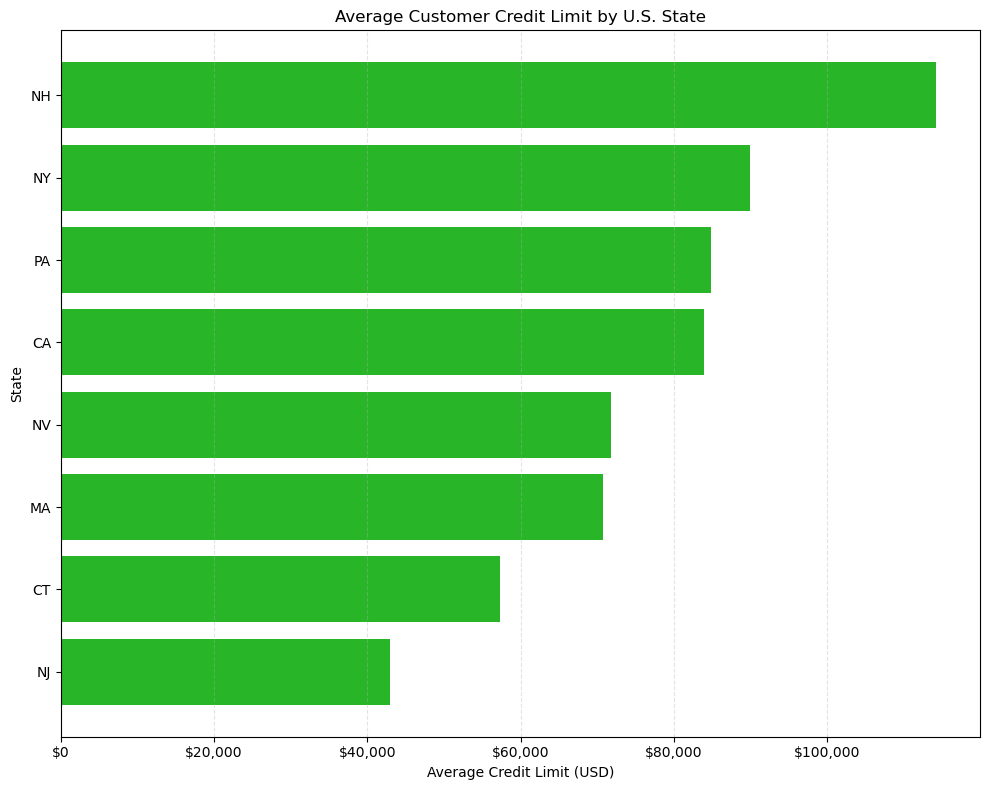

In [5]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
plot_data = USA_credit_by_state.sort_values(
    "average_credit_limit", ascending=True
)

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(plot_data["state"], plot_data["average_credit_limit"], color="#28B528")
ax.set_title("Average Customer Credit Limit by U.S. State")
ax.set_xlabel("Average Credit Limit (USD)")
ax.set_ylabel("State")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [6]:
# Replace None with your code
Top10_customers_payments = pd.read_sql_query("""
    SELECT
        c.customerNumber,
        c.customerName,
        ROUND(SUM(p.amount), 2) AS total_payments
    FROM customers AS c
    JOIN payments AS p
        ON p.customerNumber = c.customerNumber
    GROUP BY c.customerNumber, c.customerName
    ORDER BY total_payments DESC, c.customerNumber
    LIMIT 10
""", conn)

Top10_customers_payments

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

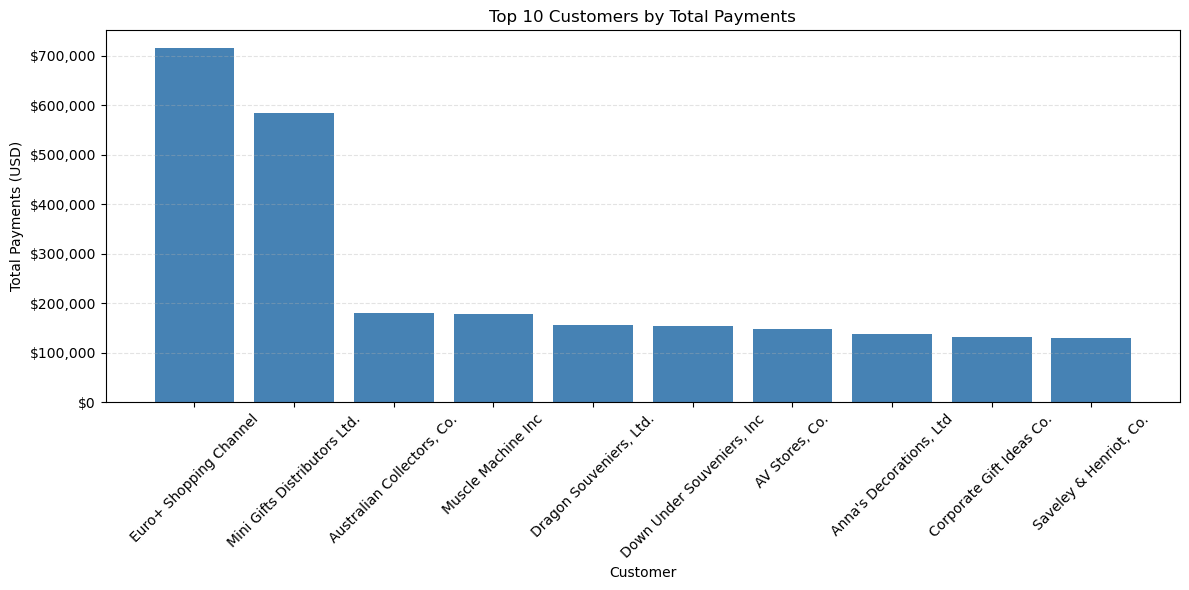

In [7]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments
plot_data = Top10_customers_payments.sort_values(
    "total_payments",
    ascending=False
)

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    plot_data["customerName"],
    plot_data["total_payments"],
    color="steelblue"
)

ax.set_title("Top 10 Customers by Total Payments")
ax.set_xlabel("Customer")
ax.set_ylabel("Total Payments (USD)")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.tick_params(axis="x", labelrotation=45)
ax.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [8]:
# Replace None with you code
customer_product_quantities = pd.read_sql_query("""
    SELECT
        c.customerNumber,
        c.customerName,
        p.productCode,
        p.productName,
        SUM(od.quantityOrdered) AS total_quantity_ordered
    FROM customers AS c
    JOIN orders AS o
        ON o.customerNumber = c.customerNumber
    JOIN orderdetails AS od
        ON od.orderNumber = o.orderNumber
    JOIN products AS p
        ON p.productCode = od.productCode
    GROUP BY
        c.customerNumber,
        c.customerName,
        p.productCode,
        p.productName
    HAVING SUM(od.quantityOrdered) >= 10
    ORDER BY
        total_quantity_ordered ASC,
        c.customerName,
        p.productName
""", conn)

customer_product_quantities

,customerNumber,customerName,productCode,productName,total_quantity_ordered
0,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
1,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [9]:
# Replace None with your code
product_line_summary = pd.read_sql_query("""
    SELECT
        p.productLine,
        COUNT(DISTINCT p.productCode) AS number_of_products,
        COALESCE(SUM(od.quantityOrdered), 0) AS total_quantity_ordered
    FROM products AS p
    LEFT JOIN orderdetails AS od
        ON od.productCode = p.productCode
    GROUP BY p.productLine
    ORDER BY total_quantity_ordered DESC
""", conn)

product_line_summary

,productLine,number_of_products,total_quantity_ordered
0,Classic Cars,38,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

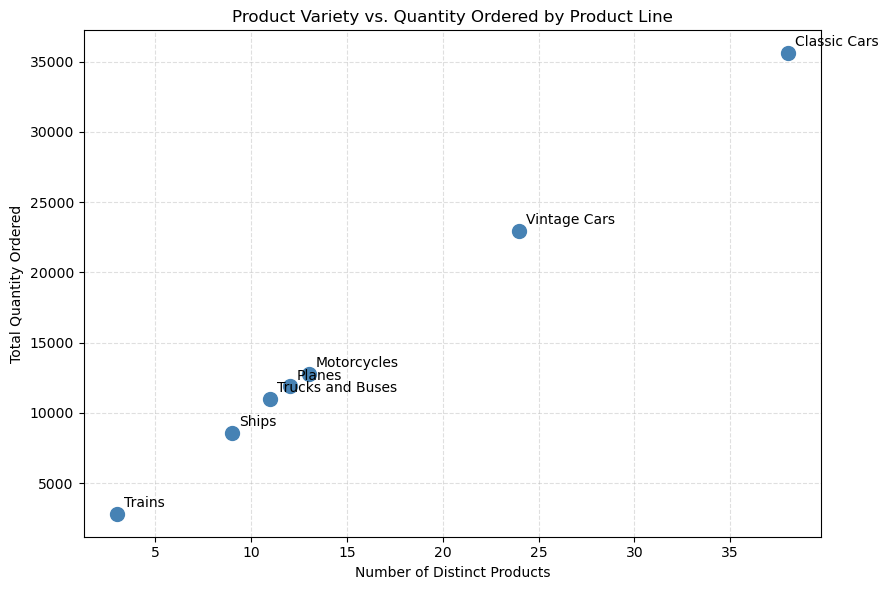

In [10]:
# Replace None with your visual code
# Produce a visual to represent the the relation between number of products and the total amount ordered
ax = product_line_summary.plot(
    kind="scatter",
    x="number_of_products",
    y="total_quantity_ordered",
    figsize=(9, 6),
    s=100,
    color="steelblue",
    title="Product Variety vs. Quantity Ordered by Product Line"
)

for _, row in product_line_summary.iterrows():
    ax.annotate(
        row["productLine"],
        (row["number_of_products"], row["total_quantity_ordered"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.set_xlabel("Number of Distinct Products")
ax.set_ylabel("Total Quantity Ordered")
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

I chose a scatter plot because it compares two numerical values for each product line: the number of distinct products and the total quantity ordered. Each point represents one product line. This lets us see whether product lines with more products also tend to have more units ordered. The chart shows a possible relationship, but it does not prove that having more products causes higher orders.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [11]:
# Replace None with your code
employees_small_offices = pd.read_sql_query("""
    SELECT
        e.employeeNumber,
        e.firstName,
        e.lastName,
        e.jobTitle,
        e.officeCode,
        o.city AS office_city,
        e.reportsTo AS supervisor_employee_number,
        m.firstName || ' ' || m.lastName AS supervisor_name,
        m.jobTitle AS supervisor_job_title
    FROM employees AS e
    JOIN offices AS o
        ON o.officeCode = e.officeCode
    LEFT JOIN employees AS m
        ON m.employeeNumber = e.reportsTo
    WHERE e.officeCode IN (
        SELECT officeCode
        FROM employees
        GROUP BY officeCode
        HAVING COUNT(*) < 5
    )
    ORDER BY e.officeCode, e.lastName, e.firstName
""", conn)

employees_small_offices

,employeeNumber,firstName,lastName,jobTitle,officeCode,office_city,supervisor_employee_number,supervisor_name,supervisor_job_title
0,1188,Julie,Firrelli,Sales Rep,2,Boston,1143,Anthony Bow,Sales Manager (NA)
1,1216,Steve,Patterson,Sales Rep,2,Boston,1143,Anthony Bow,Sales Manager (NA)
2,1286,Foon Yue,Tseng,Sales Rep,3,NYC,1143,Anthony Bow,Sales Manager (NA)
3,1323,George,Vanauf,Sales Rep,3,NYC,1143,Anthony Bow,Sales Manager (NA)
4,1625,Yoshimi,Kato,Sales Rep,5,Tokyo,1621,Mami Nishi,Sales Rep
5,1621,Mami,Nishi,Sales Rep,5,Tokyo,1056,Mary Patterson,VP Sales
6,1611,Andy,Fixter,Sales Rep,6,Sydney,1088,William Patterson,Sales Manager (APAC)
7,1619,Tom,King,Sales Rep,6,Sydney,1088,William Patterson,Sales Manager (APAC)
8,1612,Peter,Marsh,Sales Rep,6,Sydney,1088,William Patterson,Sales Manager (APAC)
9,1088,William,Patterson,Sales Manager (APAC),6,Sydney,1056,Mary Patterson,VP Sales


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!

The subquery groups employees by office and counts the employees in each group. Its HAVING COUNT(*) < 5 condition returns only the office codes for smaller offices. The main query uses those codes to select the employees and adds their office and supervisor details. So that the office list is calculated from the data instead of being hard-coded.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [12]:
# Replace None with your code
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [13]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

In [14]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [15]:
#nulls cleaning

pd.read_sql("""
SELECT COUNT(*) AS total,
       SUM(runtime_minutes IS NULL) AS null_runtime,
       SUM(genres IS NULL) AS null_genres,
       SUM(start_year IS NULL) AS null_year
FROM movie_basics
""", conn4)

,total,null_runtime,null_genres,null_year
0,146144,31739,5408,0


In [16]:
pd.read_sql("""
SELECT COUNT(*) AS total, SUM(averagerating IS NULL) AS null_rating
FROM movie_ratings
""", conn4)

,total,null_rating
0,73856,0


In [17]:
#out of range years
pd.read_sql("""
SELECT start_year, COUNT(*) AS n
FROM movie_basics
WHERE start_year > 2019 OR start_year < 2010
GROUP BY start_year
ORDER BY start_year
""", conn4)


,start_year,n
0,2020,937
1,2021,83
2,2022,32
3,2023,5
4,2024,2
5,2025,1
6,2026,1
7,2027,1
8,2115,1


In [18]:
#genres
pd.read_sql("""
SELECT genres, COUNT(*) AS n
FROM movie_basics
WHERE genres LIKE '%,%'
GROUP BY genres
ORDER BY n DESC
LIMIT 10
""", conn4)

,genres,n
0,"Comedy,Drama",3519
1,"Biography,Documentary",2115
2,"Drama,Romance",2079
3,"Comedy,Drama,Romance",1558
4,"Documentary,Drama",1554
5,"Comedy,Romance",1507
6,"Documentary,Music",1365
7,"Drama,Thriller",1335
8,"Documentary,History",1289
9,"Horror,Thriller",1253


In [19]:
#outliers
pd.read_sql("""
SELECT MIN(runtime_minutes) AS min_rt, MAX(runtime_minutes) AS max_rt,
       SUM(runtime_minutes < 40) AS under_40,
       SUM(runtime_minutes > 300) AS over_300
FROM movie_basics
WHERE runtime_minutes IS NOT NULL
""", conn4)

,min_rt,max_rt,under_40,over_300
0,1.0,51420.0,5211,123


In [20]:
#low vote ratings
pd.read_sql("""
SELECT SUM(numvotes < 10) AS under_10_votes,
       SUM(numvotes < 100) AS under_100_votes,
       COUNT(*) AS total
FROM movie_ratings
""", conn4)

,under_10_votes,under_100_votes,total
0,12146,45103,73856


In [21]:
#duplicates
print(pd.read_sql("""
SELECT COUNT(*) AS total_rows, COUNT(DISTINCT movie_id) AS unique_ids
FROM movie_basics
""", conn4))

print(pd.read_sql("""
SELECT COUNT(*) AS title_mismatch FROM movie_basics
WHERE primary_title <> original_title
""", conn4))

   total_rows  unique_ids
0      146144      146144
   title_mismatch
0           14483


In [22]:
print(pd.read_sql("""
SELECT COUNT(*) AS ratings_without_movie
FROM movie_ratings mr LEFT JOIN movie_basics mb ON mr.movie_id = mb.movie_id
WHERE mb.movie_id IS NULL
""", conn4))

print(pd.read_sql("""
SELECT COUNT(*) AS principals_without_person
FROM principals p LEFT JOIN persons pe ON p.person_id = pe.person_id
WHERE pe.person_id IS NULL
""", conn4))

   ratings_without_movie
0                      0
   principals_without_person
0                        274


In [23]:
#standardization

genres = pd.read_sql("SELECT genres FROM movie_basics WHERE genres IS NOT NULL", conn4)
sorted(genres['genres'].str.split(',').explode().str.strip().unique())

['Action',
 'Adult',
 'Adventure',
 'Animation',
 'Biography',
 'Comedy',
 'Crime',
 'Documentary',
 'Drama',
 'Family',
 'Fantasy',
 'Game-Show',
 'History',
 'Horror',
 'Music',
 'Musical',
 'Mystery',
 'News',
 'Reality-TV',
 'Romance',
 'Sci-Fi',
 'Short',
 'Sport',
 'Talk-Show',
 'Thriller',
 'War',
 'Western']

### Cleaning tasks identified
- **Nulls:** runtime missing for 30,765 movies and genres for 5,359; excluded, not imputed. Ratings have no nulls.
- **Out-of-range years:** 1,063 rows start in 2020 or later (up to 2115); filtered to 2010-2019.
- **Multi-valued genres:** 27 genres stored as comma-separated text; split into one row per genre.
- **Runtime outliers:** range of 1 to 51,420 minutes; 5,211 under 40 and 123 over 300.
- **Low-vote ratings:** 45,103 of 73,856 ratings have under 100 votes; 100+ required.
- **Titles and keys:** 14,483 primary/original title mismatches; 274 principals rows with no matching person. No duplicate movie IDs and no orphan ratings were found.
- **Standardization:** trim genre labels; bin runtimes into consistent ranges.

Which genres earn the highest audience ratings among movies released 2010-2019, and has that changed over the decade?

In [24]:
# Begin your code here
#how many movies, year range, null counts

how_many_counts_df = pd.read_sql("""
SELECT COUNT(*) AS n_movies,
       MIN(start_year) AS first_year,
       MAX(start_year) AS last_year,
       SUM(runtime_minutes IS NULL) AS null_runtime,
       SUM(genres IS NULL) AS null_genres
FROM movie_basics
WHERE start_year <= 2019
""", conn4)

how_many_counts_df

,n_movies,first_year,last_year,null_runtime,null_genres
0,145081,2010,2019,30765,5359


In [25]:
#Ratings joined to movie info

df = pd.read_sql("""
SELECT mb.movie_id, mb.primary_title, mb.start_year,
       mb.runtime_minutes, mb.genres,
       mr.averagerating, mr.numvotes
FROM movie_basics mb
JOIN movie_ratings mr ON mb.movie_id = mr.movie_id
WHERE mb.start_year BETWEEN 2010 AND 2019
  AND mb.runtime_minutes IS NOT NULL
  AND mb.genres IS NOT NULL
  AND mr.averagerating IS NOT NULL
  AND mr.numvotes >= 100
""", conn4)

print(df.shape)
df.describe()

(27965, 7)


,start_year,runtime_minutes,averagerating,numvotes
count,27965.000000,27965.000000,27965.000000,2.796500e+04
mean,2014.258680,100.892258,5.915587,9.255173e+03
std,2.573555,23.759049,1.348881,4.869203e+04
min,2010.000000,12.000000,1.000000,1.000000e+02
25%,2012.000000,88.000000,5.100000,2.080000e+02
50%,2014.000000,96.000000,6.100000,4.880000e+02
75%,2016.000000,110.000000,6.900000,1.748000e+03
max,2019.000000,1440.000000,9.900000,1.841066e+06


In [26]:
#splitting

g = df.assign(genre=df['genres'].str.split(',')).explode('genre')

genre_stats = (g.groupby('genre')
                 .agg(n_movies=('movie_id', 'count'),
                      avg_rating=('averagerating', 'mean'),
                      median_runtime=('runtime_minutes', 'median'))
                 .query('n_movies >= 100')
                 .sort_values('avg_rating', ascending=False))


In [27]:
genre_stats.round(2)

,n_movies,avg_rating,median_runtime
genre,,,
News,113,7.13,85.0
Documentary,3488,7.09,89.0
Biography,1441,6.89,102.0
Music,706,6.71,99.0
History,991,6.67,103.0
Sport,502,6.62,99.0
Animation,850,6.31,89.0
War,402,6.25,103.0
Musical,241,6.21,105.0


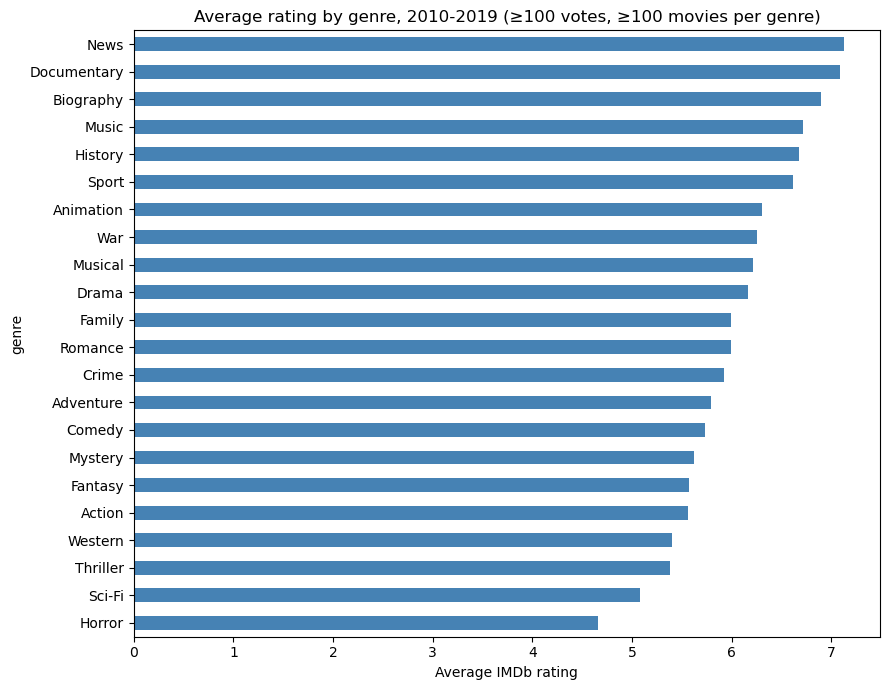

In [28]:
#Visualization

ax = genre_stats['avg_rating'].plot(kind='barh', figsize=(9, 7), color='steelblue')
ax.invert_yaxis()
ax.set_xlabel('Average IMDb rating')
ax.set_title('Average rating by genre, 2010-2019 (≥100 votes, ≥100 movies per genre)')
plt.tight_layout()
plt.show()


### Rating by Genre
In this dataset, News (7.13), Documentary (7.09), and Biography (6.89) had the highest average IMDb ratings, while Horror (4.66) and Sci-Fi (5.08) had the lowest. Drama had the largest number of movies (13,516) and an average rating of 6.17. News had only 113 movies, so its average is based on a much smaller sample and may be less representative. These results describe audience ratings in the dataset; they do not show which genres are most profitable or explain why the ratings differ.

In [29]:
import matplotlib.pyplot as plt
import numpy as np

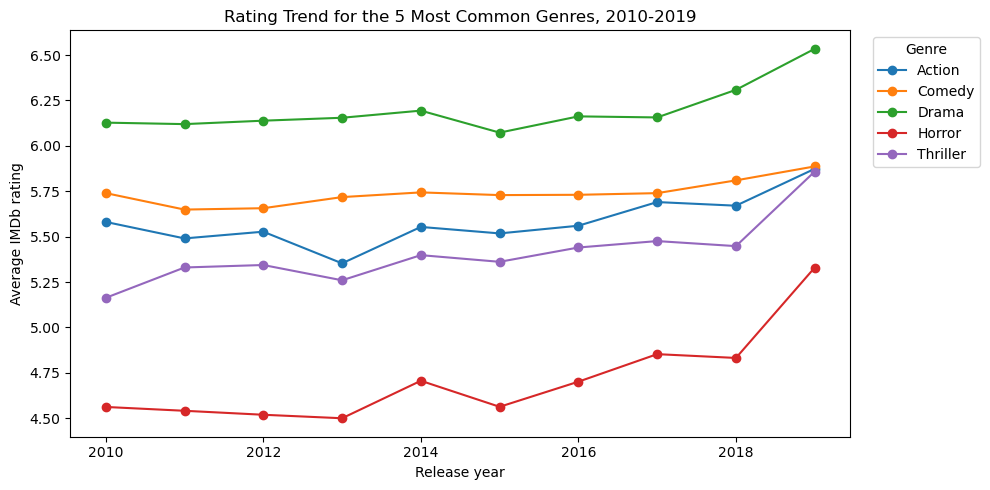

In [30]:
#Rating trend by year for top genres
top_genres = genre_stats.sort_values('n_movies', ascending=False).head(5).index
g = df.assign(genre=df['genres'].str.split(',')).explode('genre')

trend = (g[g['genre'].isin(top_genres)]
         .groupby(['start_year', 'genre'])['averagerating'].mean()
         .unstack())

fig, ax = plt.subplots(figsize=(10, 5))
trend.plot(ax=ax, marker='o')
ax.set_xlabel('Release year')
ax.set_ylabel('Average IMDb rating')
ax.set_title('Rating Trend for the 5 Most Common Genres, 2010-2019')
ax.legend(title='Genre', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


I noticed among the five most common genres, Drama is highest and Horror lowest in every year. All five rise in 2019,
with Horror and Thriller gaining roughly 0.7 points since 2010. Genre rankings are stable, so past reception is a
reasonable guide, but the 2019 jump should be checked against vote counts before drawing conclusions.

                            mean  count
genre       runtime_bucket             
Biography   <90             6.94    398
            90-120          6.81    768
            120-150         6.98    233
            150+            7.37     38
Documentary <90             7.00   2012
            90-120          7.16   1305
            120-150         7.50    104
            150+            7.74     49
History     <90             6.80    265
            90-120          6.51    498
            120-150         6.82    181
            150+            7.10     45
Music       <90             6.66    210
            90-120          6.64    399
            120-150         7.01     80
            150+            7.49     16
News        <90             7.02     84
            90-120          7.42     28
            120-150         8.20      1
Sport       <90             6.60    139
            90-120          6.51    286
            120-150         6.93     66
            150+            7.71     11


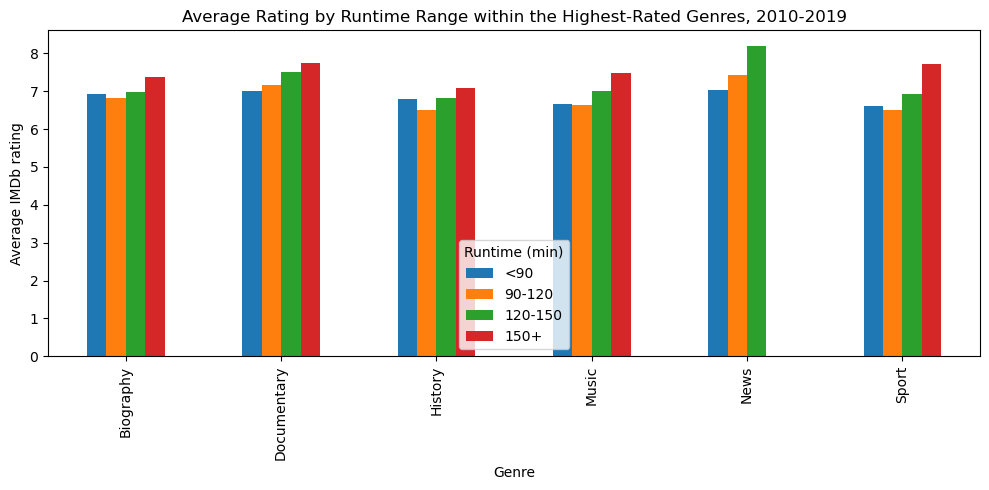

In [31]:
# Remove implausible runtimes for this analysis only
rt = g[(g['runtime_minutes'] >= 40) & (g['runtime_minutes'] <= 300)].copy()
rt['runtime_bucket'] = pd.cut(rt['runtime_minutes'], bins=[0, 90, 120, 150, 300],
                              labels=['<90', '90-120', '120-150', '150+'])

top6 = genre_stats.head(6).index  # highest-rated genres
pivot = (rt[rt['genre'].isin(top6)]
         .groupby(['genre', 'runtime_bucket'], observed=True)['averagerating']
         .agg(['mean', 'count']).round(2))
print(pivot)

heat = (rt[rt['genre'].isin(top6)]
        .pivot_table(index='genre', columns='runtime_bucket',
                     values='averagerating', aggfunc='mean', observed=True))
ax = heat.plot(kind='bar', figsize=(10, 5))
ax.set_xlabel('Genre')
ax.set_ylabel('Average IMDb rating')
ax.set_title('Average Rating by Runtime Range within the Highest-Rated Genres, 2010-2019')
ax.legend(title='Runtime (min)')
plt.tight_layout()
plt.show()

In Documentary, Biography, History and Music, the longest films (150+ minutes) have the highest average
ratings. These buckets are small (16 to 49 movies), so this is a pattern to investigate, not a conclusion.
News in the 120-150 range has only one movie.

### Limitations
IMDb ratings measure audience opinion, not profit; the database has no budget or revenue data. Multi-genre
movies are counted in each of their genres, and movies with under 100 votes were excluded.